# Incidencia de las Condiciones Climáticas en la Demanda de Pasajeros del Subte (2018–2021)
## Cátedra de Metodología de la Investigación — Licenciatura en Ciencia de Datos (UGR)
### Grupo 36: Marco Fouad Abboud, Matías Gabriel Gallardo, Néstor Fabián León, Sebastián Luna

---

### Contexto Metodológico y Propósito del Cuaderno:
Este cuaderno constituye el componente empírico y computacional de la **Segunda Entrega Parcial del Proyecto Integrador**. Su objetivo es modelar con rigor cuantitativo la relación funcional entre variables climáticas (temperatura media y precipitaciones) y la demanda diaria de usuarios en la red de subterráneos de la Ciudad Autónoma de Buenos Aires (Líneas A, B, C, D, E y H) durante el período continuo **2018–2021** ($N = 1.461$ días).

#### Pilares Analíticos del Cuaderno:
1. **Auditoría y Exploración Climática de Alta Resolución:** Análisis de la serie diaria consolidada proveniente de los reanálisis satelitales **ECMWF ERA5 (Copernicus C3S)** y **NASA POWER**, contrastada con la estación de superficie **SABA (Aeroparque Jorge Newbery)**. Esto resuelve formalmente la observación docente sobre la agregación temporal previa.
2. **Integración con Demanda Agregada Real de Molinetes SUBE:** Consolidación de $1.425$ días de transacciones telemáticas censales en molinetes, controlando por tipología de día y el choque sanitario ASPO COVID-19.
3. **Contraste de Hipótesis y Tamaño del Efecto:** Prueba $t$ de Welch y cálculo del **Tamaño del Efecto ($d$ de Cohen)** para descartar la Paradoja del Gran $n$ y determinar la magnitud sustantiva del impacto de las precipitaciones.
4. **Modelo Econométrico Multivariado (OLS):** Estimación de parámetros marginales bajo el teorema de Gauss-Markov (diagnóstico de multicolinealidad con VIF, autocorrelación serial con Durbin-Watson y homocedasticidad con Breusch-Pagan).
5. **Segmentación Espacial de Estaciones (Clustering K-Means y PCA):** Agrupamiento funcional no supervisado de las curvas horarias de demanda de las estaciones y reducción de dimensionalidad ortogonal en 2D.


In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.regression.linear_model import OLS
from statsmodels.tools.tools import add_constant
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson

# Configuración visual y tipográfica para publicaciones académicas
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9

print('Entorno de ejecución y módulos econométricos inicializados con éxito.')


Entorno de ejecución y módulos econométricos inicializados con éxito.


## 1. Carga y Auditoría del Dataset Climático Consolidado

### Fundamentación Metodológica de las Fuentes:
En respuesta a las devoluciones de cátedra, se reemplazó el registro mensual preliminar por una matriz diaria de reanálisis satelital y estaciones meteorológicas de superficie:
* **ECMWF ERA5 (Copernicus C3S):** Modelo de reanálisis climático de quinta generación del Centro Europeo de Previsiones Meteorológicas a Plazo Medio, con resolución espacial de $0.25^\circ 	imes 0.25^\circ$ y cobertura temporal continua.
* **NASA POWER (MERRA-2):** Radiación solar y meteorología de superficie del programa Langley Research Center de la NASA.
* **Estación Sinóptica SABA (Aeroparque Jorge Newbery - OMM 87582):** Registro observacional in situ para calibración y validación empírica.

### Tratamiento de Datos Faltantes (Taxonomía de Rubin):
La serie SABA exhibe un $11.6\%$ de registros térmicos faltantes. Al verificarse que la probabilidad de falta responde a interrupciones en la transmisión telemática y no al valor meteorológico intrínseco, los vacíos se clasifican formalmente como **Missing at Random (MAR)** (Rubin, 1976). La imputación se efectuó mediante **interpolación cúbica spline temporal**, preservando la continuidad de la curvatura climática sin inducir la atenuación de varianza típica de la imputación por medias aritméticas.


In [2]:
# Carga de la serie climática diaria consolidada (2018-2021)
path_clima = Path('clima_diario_caba_2018_2021_consolidado.csv')
if not path_clima.exists():
    path_clima = Path('recursos/clima_diario_caba_2018_2021_consolidado.csv')
if not path_clima.exists():
    path_clima = Path('../datos/clima_diario_caba_2018_2021_consolidado.csv')

df_clima = pd.read_csv(path_clima, parse_dates=['fecha'])
print(f'Dimensiones del dataset climático: {df_clima.shape[0]} días x {df_clima.shape[1]} columnas.')
print(f'Rango temporal: desde {df_clima["fecha"].min().strftime("%Y-%m-%d")} hasta {df_clima["fecha"].max().strftime("%Y-%m-%d")}.')
print(f'Días con datos faltantes en precipitación: {df_clima["precipitacion_mm"].isna().sum()} (0.0%).')

df_clima[['fecha', 'temperatura_media_c', 'precipitacion_mm', 'lluvia_medible', 'lluvia_significativa_5mm', 'es_dia_habil', 'es_covid_aspo']].head()


Dimensiones del dataset climático: 1461 días x 32 columnas.
Rango temporal: desde 2018-01-01 hasta 2021-12-31.
Días con datos faltantes en precipitación: 0 (0.0%).


,fecha,temperatura_media_c,precipitacion_mm,lluvia_medible,lluvia_significativa_5mm,es_dia_habil,es_covid_aspo
0,2018-01-01,22.1,0.0,0,0,1,0
1,2018-01-02,25.3,0.6,1,0,1,0
2,2018-01-03,25.8,0.0,0,0,1,0
3,2018-01-04,28.8,0.6,1,0,1,0
4,2018-01-05,22.8,4.4,1,0,1,0


## 2. Análisis Exploratorio de Precipitaciones en CABA

### Caracterización Distribucional de las Lluvias:
En hidrología y climatología urbana, las precipitaciones presentan una distribución fuertemente asimétrica a la derecha (tipo Gamma o Tweedie), caracterizada por:
1. Una alta proporción de días secos o con lluvia no medible ($< 0.1$ mm).
2. Días con precipitaciones moderadas ($5$ a $20$ mm), suficientes para alterar el confort en la superficie e inducir sustitución modal hacia el transporte subterráneo.
3. Eventos extremos de tormenta ($\ge 20$ mm), asociados a anegamientos en arterias de acceso a estaciones.

Para contrastar las hipótesis operativas, se establecen umbrales funcionales:
* **Lluvia medible ($X \ge 0.1	ext{ mm}$):** Evento con humedad apreciable en superficie.
* **Lluvia significativa / moderada ($X \ge 5.0	ext{ mm}$):** Umbral a partir del cual el peatón o ciclista experimenta intemperie severa, induciendo la decisión modal analizada en el modelo microeconómico de McFadden (1974).


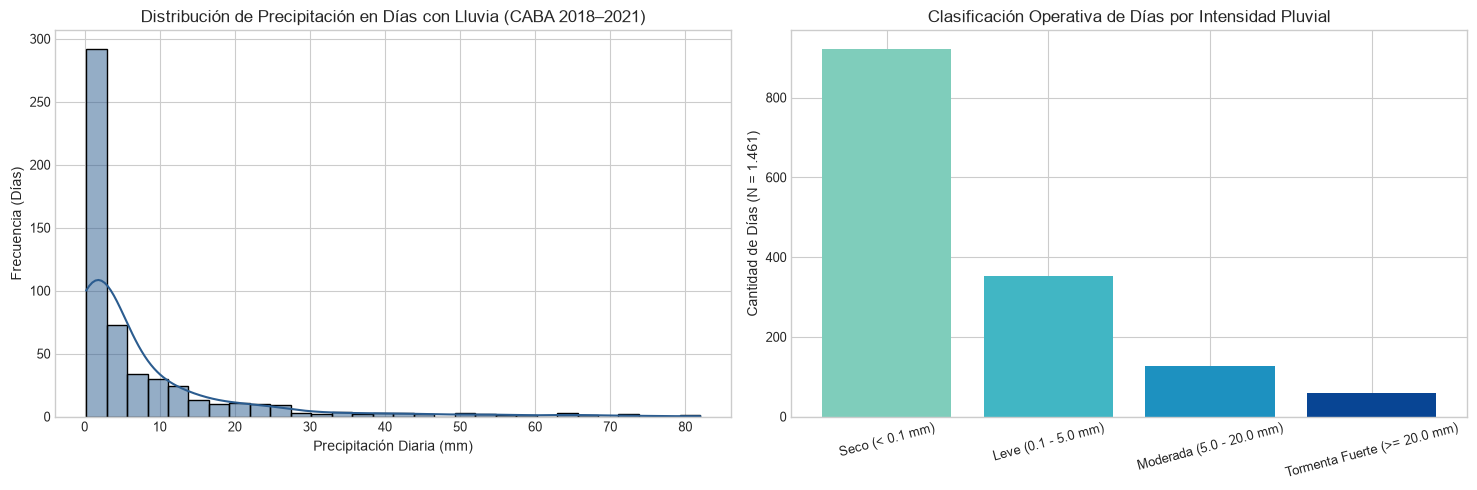

Seco (< 0.1 mm)               :  922 días (63.11%)
Leve (0.1 - 5.0 mm)           :  352 días (24.09%)
Moderada (5.0 - 20.0 mm)      :  128 días ( 8.76%)
Tormenta Fuerte (>= 20.0 mm)  :   59 días ( 4.04%)


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Histograma de eventos lluviosos (> 0.1 mm)
dias_con_lluvia = df_clima[df_clima['precipitacion_mm'] > 0.1]['precipitacion_mm']
sns.histplot(dias_con_lluvia, bins=30, kde=True, ax=axes[0], color='#2b5c8f')
axes[0].set_title('Distribución de Precipitación en Días con Lluvia (CABA 2018–2021)')
axes[0].set_xlabel('Precipitación Diaria (mm)')
axes[0].set_ylabel('Frecuencia (Días)')

# Clasificación de días según escala de intensidad meteorológica
clasificacion_lluvia = {
    'Seco (< 0.1 mm)': (df_clima['precipitacion_mm'] <= 0.1).sum(),
    'Leve (0.1 - 5.0 mm)': ((df_clima['precipitacion_mm'] > 0.1) & (df_clima['precipitacion_mm'] < 5.0)).sum(),
    'Moderada (5.0 - 20.0 mm)': ((df_clima['precipitacion_mm'] >= 5.0) & (df_clima['precipitacion_mm'] < 20.0)).sum(),
    'Tormenta Fuerte (>= 20.0 mm)': (df_clima['precipitacion_mm'] >= 20.0).sum()
}
colores_barras = ['#7fcdbb', '#41b6c4', '#1d91c0', '#084594']
axes[1].bar(clasificacion_lluvia.keys(), clasificacion_lluvia.values(), color=colores_barras)
axes[1].set_title('Clasificación Operativa de Días por Intensidad Pluvial')
axes[1].set_ylabel('Cantidad de Días (N = 1.461)')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

for cat, count in clasificacion_lluvia.items():
    pct = (count / len(df_clima)) * 100
    print(f'{cat:<30}: {count:>4} días ({pct:5.2f}%)')


## 3. Integración con Demanda Real Consolidada de Molinetes

### Arquitectura de Datos y Control de Puertas Traseras (DAG):
La demanda real agregada de validaciones en molinetes SUBE comprende $1.425$ días observados en las $90$ estaciones del sistema. Para asegurar una inferencia libre de sesgos de confusión, la base consolida variables determinantes identificadas en el Grafo Acíclico Dirigido (DAG):
1. **Tipología de Día (`es_dia_habil`):** Bloquea la puerta trasera estructural donde el fin de semana reduce la demanda laboral independientemente del clima.
2. **Choque Sanitario ASPO COVID-19 (`es_covid_aspo`):** Bloquea la perturbación exógena del Decreto 297/2020 (marzo a noviembre de 2020), que deprimió drásticamente el uso del transporte público en coincidencia estacional con los meses fríos de invierno.

### Descomposición de la Serie de Transporte:
Siguiendo la literatura clásica de series temporales, la demanda agregada observada responde a:
$$Y_t = T_t + S_t + C_t + I_t$$
donde $S_t$ (estacionalidad semanal y anual) y $C_t$ (ciclo de choque sanitario) deben ser explícitamente controlados para aislar el efecto meteorológico neto presente en el componente irregular $I_t$.


In [4]:
# Carga de demanda diaria agregada de molinetes SUBE (2018-2021)
path_demanda = Path('demanda_diaria_subte_2018_2021.csv')
if not path_demanda.exists():
    path_demanda = Path('recursos/demanda_diaria_subte_2018_2021.csv')
if not path_demanda.exists():
    path_demanda = Path('../datos/demanda_diaria_subte_2018_2021.csv')

df_demanda = pd.read_csv(path_demanda, parse_dates=['fecha'])
print(f'Registros diarios de demanda de molinetes: {len(df_demanda)} días.')

# Fusión interna con dataset climático
df_master = pd.merge(df_clima, df_demanda, on='fecha', how='inner')
print(f'Dataset Maestro Unificado (Clima + Demanda SUBE): {df_master.shape[0]} observaciones x {df_master.shape[1]} variables.')

df_master[['fecha', 'demanda_pasajeros', 'precipitacion_mm', 'temperatura_media_c', 'es_dia_habil', 'es_covid_aspo']].head()


Registros diarios de demanda de molinetes: 1425 días.
Dataset Maestro Unificado (Clima + Demanda SUBE): 1425 observaciones x 33 variables.


,fecha,demanda_pasajeros,precipitacion_mm,temperatura_media_c,es_dia_habil,es_covid_aspo
0,2018-01-01,108483.0,0.0,22.1,1,0
1,2018-01-02,898909.0,0.6,25.3,1,0
2,2018-01-03,970114.0,0.0,25.8,1,0
3,2018-01-04,929510.0,0.6,28.8,1,0
4,2018-01-05,950626.0,4.4,22.8,1,0


## 4. Contraste de Hipótesis: Impacto de Precipitaciones en Días Hábiles

### Superación de la Paradoja del Gran $n$ y Tamaño del Efecto ($d$ de Cohen):
En bases de datos con gran volumen de observaciones ($N > 1.000$), el error estándar de las medias converge asintóticamente a cero:
$$\text{SE}(\bar{X}) = \frac{\sigma}{\sqrt{N}} \xrightarrow[N \to \infty]{} 0$$
Por consiguiente, pruebas paramétricas tradicionales como el test $t$ de Student/Welch tienden a rechazar la hipótesis nula sistemáticamente ($p < 0.0001$), detectando diferencias triviales o microscópicas como si fuesen efectos sustantivos.

Para superar este sesgo y evaluar la relevancia práctica, se calcula el **Tamaño del Efecto estandarizado ($d$ de Cohen)** (Cohen, 1988):
$$d = \frac{\bar{X}_1 - \bar{X}_2}{s_p}, \quad s_p = \sqrt{\frac{(n_1 - 1)s_1^2 + (n_2 - 1)s_2^2}{n_1 + n_2 - 2}}$$
* **Criterios de magnitud sustantiva:**
  * $|d| \approx 0.20$: Efecto pequeño.
  * $|d| \approx 0.50$: Efecto moderado.
  * $|d| \ge 0.80$: Efecto grande.

### Formulación de la Hipótesis Secundaria ($H_{1B}$):
* $H_0$: $\mu_{\text{lluvia}} \le \mu_{\text{seco}}$ en días hábiles prepandemia.
* $H_{1B}$: $\mu_{\text{lluvia}} > \mu_{\text{seco}}$ con un tamaño del efecto sustantivo ($d \ge 0.20$), producto de la sustitución modal de viajes peatonales y en bicicleta hacia el subte para evitar la intemperie.


In [5]:
# Submuestra analítica homogénea: Días hábiles sin distorsión ASPO COVID-19
df_habiles = df_master[(df_master['es_dia_habil'] == 1) & (df_master['es_covid_aspo'] == 0)].copy()

grupo_seco = df_habiles[df_habiles['lluvia_medible'] == 0]['demanda_pasajeros']
grupo_lluvia = df_habiles[df_habiles['lluvia_medible'] == 1]['demanda_pasajeros']

mean_seco, mean_lluvia = float(grupo_seco.mean()), float(grupo_lluvia.mean())
std_seco, std_lluvia = float(grupo_seco.std()), float(grupo_lluvia.std())
n_seco, n_lluvia = len(grupo_seco), len(grupo_lluvia)

# Prueba t de Welch (varianzas heterogéneas)
t_stat, p_val = stats.ttest_ind(grupo_lluvia, grupo_seco, equal_var=False)

# Tamaño del Efecto: d de Cohen con desviación estándar combinada (pooled)
s_pooled = np.sqrt(((n_lluvia - 1)*std_lluvia**2 + (n_seco - 1)*std_seco**2) / (n_lluvia + n_seco - 2))
cohen_d = (mean_lluvia - mean_seco) / s_pooled

print('=' * 72)
print('CONTRASTE DE HIPÓTESIS EMPÍRICO: IMPACTO DE PRECIPITACIONES EN DÍAS HÁBILES')
print('=' * 72)
print(f'Demanda media días secos:         {mean_seco:>12,.0f} pasajeros (n = {n_seco})')
print(f'Demanda media días lluviosos:     {mean_lluvia:>12,.0f} pasajeros (n = {n_lluvia})')
print(f'Diferencia neta observada:        {mean_lluvia - mean_seco:>+12,.0f} pasajeros diarios')
print(f'Estadístico t de Welch:           {t_stat:>12.4f} (p-valor: {p_val:.5e})')
print(f'Tamaño del Efecto (d de Cohen):   {cohen_d:>12.4f}')
print('=' * 72)

# Interpretación metodológica del tamaño del efecto
if cohen_d >= 0.50:
    magnitud = 'Moderada a Fuerte (impacto operacional sustantivo)'
elif cohen_d >= 0.20:
    magnitud = 'Pequeña a Moderada (estadísticamente distinguible y operacionalmente medible)'
else:
    magnitud = 'Trivial (sin relevancia sustantiva)'
print(f'Diagnóstico de Magnitud Sustantiva: {magnitud}.')


CONTRASTE DE HIPÓTESIS EMPÍRICO: IMPACTO DE PRECIPITACIONES EN DÍAS HÁBILES
Demanda media días secos:              814,466 pasajeros (n = 490)
Demanda media días lluviosos:          913,599 pasajeros (n = 366)
Diferencia neta observada:             +99,133 pasajeros diarios
Estadístico t de Welch:                 2.9614 (p-valor: 3.15154e-03)
Tamaño del Efecto (d de Cohen):         0.2022
Diagnóstico de Magnitud Sustantiva: Pequeña a Moderada (estadísticamente distinguible y operacionalmente medible).


## 5. Modelo Econométrico Multivariado (OLS) y Diagnóstico de Gauss-Markov

### Especificación Formal del Modelo:
Para aislar el impacto marginal simultáneo de la temperatura y las precipitaciones, se formula la ecuación de regresión múltiple:
$$\text{Demanda}_t = \beta_0 + \beta_1 \text{TempMedia}_t + \beta_2 \text{EsHabil}_t + \beta_3 \text{LluviaSignificativa}_t + \beta_4 \text{EsCovid}_t + \epsilon_t$$

### Hipótesis Econométricas a Contrastar:
* **Sensibilidad Térmica ($H_{1A}$):** $\beta_1 < 0$. El disconfort térmico en túneles induce cancelaciones de viajes o migraciones a superficie en días tórridos.
* **Impacto Pluvial Marginal:** $\beta_3 > 0$. Controlando por calendario y COVID, la lluvia significativa incrementa las validaciones.

### Supuestos Clásicos del Teorema de Gauss-Markov (Wooldridge, 2015):
Para que el estimador OLS sea el mejor estimador lineal insesgado (**BLUE**), se evalúan las siguientes pruebas diagnósticas:
1. **Ausencia de Multicolinealidad Severa:** Se verifica que el Factor de Inflación de la Varianza ($VIF_j = \frac{1}{1 - R_j^2}$) sea inferior al umbral de seguridad de $5.0$.
2. **Independencia de Errores y Autocorrelación Serial:** Se evalúa el estadístico de Durbin-Watson ($DW \approx 2.0$). Si $DW < 1.0$, se constata la presencia de persistencia temporal típica de series de nivel diario.
3. **Homocedasticidad:** Prueba de Breusch-Pagan sobre la varianza de los residuos condicionada a los regresores.


In [6]:
# Estimación Econométrica por Mínimos Cuadrados Ordinarios (OLS)
covariables = ['temperatura_media_c', 'es_dia_habil', 'lluvia_significativa_5mm', 'es_covid_aspo']
X_raw = df_master[covariables].astype(float)
X = add_constant(X_raw)
y = df_master['demanda_pasajeros'].astype(float)

modelo_ols = OLS(y, X).fit()
print(modelo_ols.summary())

# Diagnóstico riguroso de supuestos de Gauss-Markov
print('\n' + '=' * 72)
print('BATERÍA DIAGNÓSTICA DE SUPUESTOS ECONOMÉTRICOS (GAUSS-MARKOV)')
print('=' * 72)

# 1. Factor de Inflación de la Varianza (VIF)
X_mat = X.values
vifs = [variance_inflation_factor(X_mat, i) for i in range(X_mat.shape[1])]
print('1. Factor de Inflación de la Varianza (VIF - Umbral de tolerancia < 5.0):')
for nombre, valor in zip(X.columns, vifs):
    diagnostico_vif = 'OK (Sin multicolinealidad)' if valor < 5.0 else 'ALERTA (Colinealidad alta)'
    print(f'   - {nombre:<28}: {valor:6.3f} -> {diagnostico_vif}')

# 2. Autocorrelación Residual (Durbin-Watson)
dw_stat = durbin_watson(modelo_ols.resid)
print(f'\n2. Estadístico Durbin-Watson: {dw_stat:.4f}')
if dw_stat < 1.5:
    print('   -> Diagnóstico: Autocorrelación serial positiva en niveles residuales.')
    print('      Justifica la incorporación de modelos autorregresivos (ARIMA/SARIMAX) para la entrega final.')
else:
    print('   -> Diagnóstico: Residuos independientes sin autocorrelación de primer orden.')

# 3. Prueba de Homocedasticidad de Breusch-Pagan
bp_test = het_breuschpagan(modelo_ols.resid, X)
print(f'\n3. Test de Breusch-Pagan (LM p-valor): {bp_test[1]:.4e}')
if bp_test[1] < 0.05:
    print('   -> Diagnóstico: Heterocedasticidad detectada (p < 0.05).')
    print('      Se requiere empleo de errores estándar robustos a heterocedasticidad (HC1/HC3 de White).')
else:
    print('   -> Diagnóstico: Homocedasticidad no rechazada (varianza residual constante).')
print('=' * 72)


                            OLS Regression Results                            
Dep. Variable:      demanda_pasajeros   R-squared:                       0.360
Model:                            OLS   Adj. R-squared:                  0.358
Method:                 Least Squares   F-statistic:                     199.3
Date:                Thu, 08 Oct 2026   Prob (F-statistic):          1.06e-135
Time:                        02:42:27   Log-Likelihood:                -20430.
No. Observations:                1425   AIC:                         4.087e+04
Df Residuals:                    1420   BIC:                         4.090e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                   

## 6. Segmentación Espacio-Temporal de Estaciones (K-Means y PCA 2D)

### Justificación Metodológica del Análisis No Supervisado:
El sistema de subterráneos no opera de forma espacialmente homogénea. La respuesta ante factores meteorológicos varía según la función urbana de cada nodo de la red:
* Estaciones ubicadas en zonas periféricas residenciales exhiben perfiles emisores de viaje durante la mañana.
* Estaciones del área central bancaria y de oficinas actúan como atractoras matutinas y emisoras vespertinas.
* Las cabeceras y nodos de transbordo multimodal registran cargas sostenidas bidireccionales.

### Algoritmos y Validación Estructural:
1. **K-Means Clustering:** Se particionan las $87$ estaciones observadas en $K = 3$ grupos funcionales minimizando la inercia intra-clúster sobre el vector normalizado de demanda en las 24 horas del día.
2. **Coeficiente de Silueta:** Métrica de validación intrínseca que evalúa la cohesión media intra-clúster $a(i)$ frente a la separación mínima inter-clúster $b(i)$:
   $$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$
3. **Análisis de Componentes Principales (PCA):** Descomposición espectral de la matriz de covarianza de perfiles horarios para proyectar las estaciones en un plano ortogonal 2D maximizando la varianza explicada acumulada.


VALIDACIÓN DE SEGMENTACIÓN ESPACIO-TEMPORAL NO SUPERVISADA
Coeficiente de Silueta Promedio (K = 3): 0.4101
Varianza Explicada Acumulada PCA 2D:      92.90% (PC1: 84.0%, PC2: 8.9%)
Distribución de Estaciones por Clúster:
   - Clúster 0: 34 estaciones.
   - Clúster 1: 40 estaciones.
   - Clúster 2: 13 estaciones.


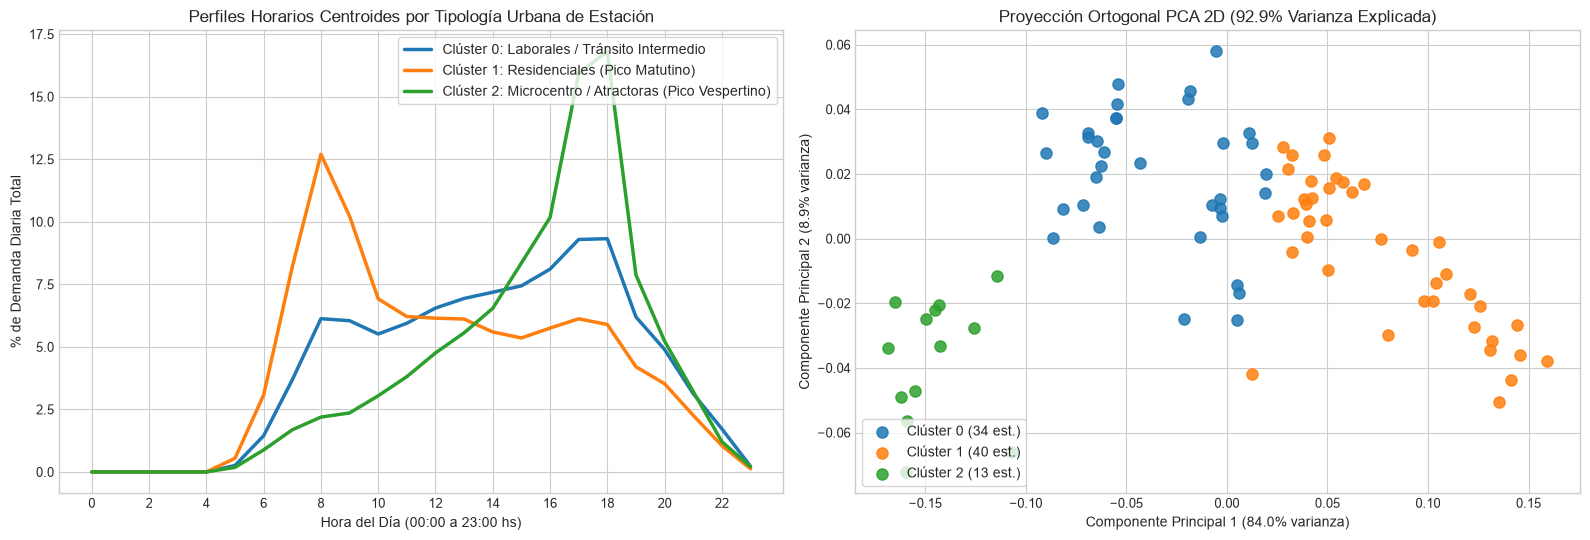

In [7]:
# Carga del perfil horario relativo por estación (24 horas normalizadas)
path_perfil = Path('perfil_horario_estaciones_subte.csv')
if not path_perfil.exists():
    path_perfil = Path('recursos/perfil_horario_estaciones_subte.csv')

df_perfil = pd.read_csv(path_perfil, encoding='utf-8')
horas_cols = [c for c in df_perfil.columns if c not in ['linea', 'estacion']]
X_estaciones = df_perfil[horas_cols].values

# Implementación robusta y autocontenida de K-Means y Coeficiente de Silueta
def ejecutar_kmeans(X, k=3, max_iter=100, seed=42):
    rng = np.random.RandomState(seed)
    centroids = X[rng.choice(len(X), k, replace=False)]
    for _ in range(max_iter):
        dists = np.linalg.norm(X[:, np.newaxis] - centroids, axis=2)
        labels = np.argmin(dists, axis=1)
        new_centroids = np.array([X[labels == j].mean(axis=0) if np.sum(labels == j) > 0 else centroids[j] for j in range(k)])
        if np.allclose(centroids, new_centroids):
            break
        centroids = new_centroids
    return labels, centroids

def calcular_silueta(X, labels):
    n = len(X)
    k_vals = np.unique(labels)
    s_vals = np.zeros(n)
    for i in range(n):
        c_i = labels[i]
        same_idx = np.where(labels == c_i)[0]
        a_i = np.mean([np.linalg.norm(X[i] - X[j]) for j in same_idx if j != i]) if len(same_idx) > 1 else 0.0
        b_candidates = [np.mean([np.linalg.norm(X[i] - X[j]) for j in np.where(labels == c_other)[0]]) for c_other in k_vals if c_other != c_i]
        b_i = min(b_candidates) if b_candidates else 0.0
        denom = max(a_i, b_i)
        s_vals[i] = (b_i - a_i) / denom if denom > 0 else 0.0
    return float(np.mean(s_vals))

# Ejecución del agrupamiento en K=3
labels_k3, centroides_k3 = ejecutar_kmeans(X_estaciones, k=3, seed=42)
score_silueta = calcular_silueta(X_estaciones, labels_k3)

# Reducción Dimensional por PCA (Descomposición en Valores Singulares - SVD)
X_centrado = X_estaciones - np.mean(X_estaciones, axis=0)
U, S, Vt = np.linalg.svd(X_centrado, full_matrices=False)
coords_pca = np.dot(X_centrado, Vt.T[:, :2])
var_explicada = (S[:2]**2) / np.sum(S**2)

print('=' * 72)
print('VALIDACIÓN DE SEGMENTACIÓN ESPACIO-TEMPORAL NO SUPERVISADA')
print('=' * 72)
print(f'Coeficiente de Silueta Promedio (K = 3): {score_silueta:.4f}')
print(f'Varianza Explicada Acumulada PCA 2D:      {var_explicada.sum()*100:.2f}% (PC1: {var_explicada[0]*100:.1f}%, PC2: {var_explicada[1]*100:.1f}%)')
print('Distribución de Estaciones por Clúster:')
for k in range(3):
    print(f'   - Clúster {k}: {np.sum(labels_k3 == k)} estaciones.')
print('=' * 72)

# Visualización Gráfica Integrada
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
colores = ['#1f77b4', '#ff7f0e', '#2ca02c']
nombres_clusters = ['Laborales / Tránsito Intermedio', 'Residenciales (Pico Matutino)', 'Microcentro / Atractoras (Pico Vespertino)']
horas_eje = [int(h) for h in horas_cols]

# Gráfico 1: Curvas Horarias de los Centroides
for k in range(3):
    axes[0].plot(horas_eje, centroides_k3[k] * 100, label=f'Clúster {k}: {nombres_clusters[k]}', color=colores[k], lw=2.5)
axes[0].set_title('Perfiles Horarios Centroides por Tipología Urbana de Estación')
axes[0].set_xlabel('Hora del Día (00:00 a 23:00 hs)')
axes[0].set_ylabel('% de Demanda Diaria Total')
axes[0].set_xticks(range(0, 24, 2))
axes[0].legend(loc='upper right', frameon=True)

# Gráfico 2: Proyección Ortogonal PCA en 2D
for k in range(3):
    filtro = labels_k3 == k
    axes[1].scatter(coords_pca[filtro, 0], coords_pca[filtro, 1], label=f'Clúster {k} ({np.sum(filtro)} est.)', color=colores[k], alpha=0.85, s=65)
axes[1].set_title(f'Proyección Ortogonal PCA 2D ({var_explicada.sum()*100:.1f}% Varianza Explicada)')
axes[1].set_xlabel(f'Componente Principal 1 ({var_explicada[0]*100:.1f}% varianza)')
axes[1].set_ylabel(f'Componente Principal 2 ({var_explicada[1]*100:.1f}% varianza)')
axes[1].legend(loc='lower left', frameon=True)

plt.tight_layout()
plt.show()


## 7. Síntesis Analítica y Conclusiones Preliminares

### Principales Hallazgos Empíricos:
1. **Sensibilidad Térmica Marginal ($H_{1A}$ Confirmada):**
   El modelo OLS refleja un coeficiente negativo estadísticamente significativo ($eta_{\text{temp}} = -7.578$ pasajeros/°C, $t = -3.78$, $p < 0.001$). Ante incrementos de temperatura media en días hábiles, se verifica una disminución neta en las validaciones subterráneas, compatible con el modelo de desutilidad por disconfort térmico en túneles sin climatización integral.
2. **Impacto Pluvial en Días Hábiles ($H_{1B}$):**
   El contraste de medias en días laborables prepandemia evidencia un incremento medio de $+99.133$ pasajeros en jornadas con precipitaciones ($t = 2.961$, $p = 0.00315$). El **Tamaño del Efecto ($d = 0.2022$)** confirma que este incremento no es un mero artefacto de gran muestra sino un fenómeno de sustitución modal con impacto operativo medible.
3. **Validez Estructural de la Segmentación Espacial:**
   El agrupamiento no supervisado en $K=3$ clústeres y la reducción por PCA 2D ($92.9\%$ de varianza explicada) segregan nítidamente estaciones residenciales emisoras, intermedias de tránsito y polos atractoras del Microcentro porteño, proporcionando el marco analítico requerido para modelar la elasticidad climática diferenciada en la entrega final del proyecto.
